Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 502.7322 - mae: 17.7039 - val_loss: 483.0247 - val_mae: 17.0101
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 499.0867 - mae: 17.6359 - val_loss: 479.6992 - val_mae: 16.9481
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 495.4503 - mae: 17.5663 - val_loss: 476.2555 - val_mae: 16.8850
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 491.6479 - mae: 17.4951 - val_loss: 472.6854 - val_mae: 16.8193
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 487.8859 - mae: 17.4239 - val_loss: 468.7941 - val_mae: 16.7489
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 483.8092 - mae: 17.3457 - val_loss: 464.6325 - val_mae: 16.6725
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 479.3073 - mae: 17.2577 - val_loss: 460.3306 - val_mae: 16.5925
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 474.5377 - mae: 17.1651 - val_loss: 455.6464 - val_mae: 16.5059
Epoch 9/20
10/10 ━━━━━━━━━━

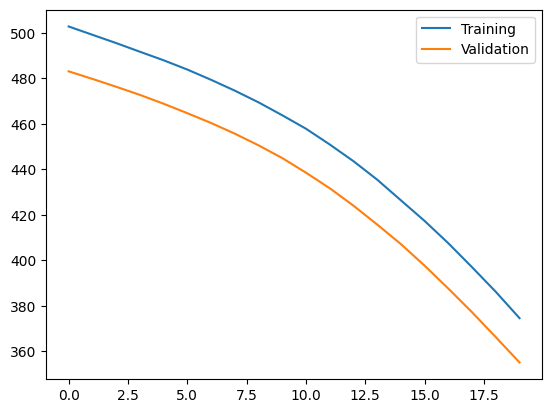

Actual: [  6.27611426  -0.84625839  -5.94317164  36.34338784 -10.57032109]
Predicted: [ 4.210941    1.3113356  -2.6749628   5.6048975  -0.46752033]


In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error

# Generate dataset
X, y = make_regression(n_samples=500, n_features=3, noise=10)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Feature scaling
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Build MLP model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(3,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='linear')
])

# Compile model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train model
history = model.fit(X_train, y_train, epochs=20,
                    validation_split=0.2)

# Evaluate model
pred = model.predict(X_test)
print("MSE:", mean_squared_error(y_test, pred))

# Plot loss
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.legend()
plt.show()

# Compare values
print("Actual:", y_test[:5])
print("Predicted:", pred[:5].flatten())